# Part 3: Vocabulários visuais e PCA

Compara vocabulários pequenos com vocabulários maiores, com e sem PCA dos vetores de imagem. Os histogramas BoVW são globais: dimensão K.

Os vocabulários são reaprendidos apenas nas imagens de treino de cada experiência, evitando que a validação interna participe na sua aprendizagem. Os splits internos são por imagem, comuns a todas as categorias, K e representações. A seleção usa apenas validação interna; as comparações finais são predefinidas.

O split externo é o `val` fornecido e permanece separado do treino deste notebook. Já foi explorado na Part 1: estes resultados devem ser apresentados como avaliação externa reutilizada, não como teste nunca consultado. Para uma avaliação independente, definir `PART3_TEST_SPLITS` e `PART3_TEST_IMAGES` com novos splits/imagens compatíveis, sem imagens de treino. O notebook não inventa um teste independente.

A primeira execução é mais demorada: mede SIFT, aprendizagem dos vocabulários e encoding. Os caches próprios guardam os tempos medidos e a origem dos dados, sem alterar os ficheiros da Part 1.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import platform
import json
import hashlib
import joblib
import cv2
import warnings
from pathlib import Path
from time import perf_counter
from inspect import signature
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, accuracy_score, f1_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display
from src import utils
from src.features import computeFeatures

PART3_ROOT = Path("data")
PART3_OUTPUT = Path("results/part3_complete")
PART3_CACHE = PART3_OUTPUT / "cache"
PART3_TEST_SPLITS = None
PART3_TEST_IMAGES = None
PART3_CATEGORIES = ("motorbike", "aeroplane", "person", "horse", "car")
PART3_SEEDS = (42, 43, 44)
PART3_DIMS = (128, 256)
PART3_VAL_FRACTION = 0.2
PART3_C = 10.0
PART3_SAMPLE_IMAGES_PER_CLASS = 100
PART3_SAMPLE_DESCRIPTORS = 128
PART3_MAX_DESCRIPTORS = 2000
PART3_METHODS = {"bovw": (128, 256, 512, 1024)}
SVM_DEFAULTS = signature(utils.train_svm).parameters
SVM_MAX_ITER = SVM_DEFAULTS["max_iter"].default
SVM_TOL = SVM_DEFAULTS["tol"].default
SVM_SEED = SVM_DEFAULTS["seed"].default
PART3_VERSION = "bovw-only-v1"
PART3_OUTPUT.mkdir(parents=True, exist_ok=True)
PART3_CACHE.mkdir(parents=True, exist_ok=True)

part3_environment = {"python": platform.python_version(), "numpy": np.__version__,
    "sklearn": sklearn.__version__, "platform": platform.platform(),
    "processor": platform.processor(), "C": PART3_C,
    "svm_max_iter": SVM_MAX_ITER, "svm_tol": SVM_TOL, "svm_seed": SVM_SEED,
    "seeds": PART3_SEEDS, "methods": PART3_METHODS,
    "sample_images_per_class": PART3_SAMPLE_IMAGES_PER_CLASS,
    "sample_descriptors_per_image": PART3_SAMPLE_DESCRIPTORS,
    "max_descriptors_per_image": PART3_MAX_DESCRIPTORS,
    "test_splits": str(PART3_TEST_SPLITS), "test_images": str(PART3_TEST_IMAGES),
    "version": PART3_VERSION}
display(part3_environment)
(PART3_OUTPUT / "environment.json").write_text(
    json.dumps(part3_environment, ensure_ascii=False, indent=2), encoding="utf-8")


{'python': '3.11.18',
 'numpy': '2.4.6',
 'sklearn': '1.9.1',
 'platform': 'Windows-10-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 186 Stepping 2, GenuineIntel',
 'C': 10.0,
 'svm_max_iter': 200000,
 'svm_tol': 0.0001,
 'svm_seed': 42,
 'seeds': (42, 43, 44),
 'methods': {'bovw': (128, 256, 512, 1024)},
 'sample_images_per_class': 100,
 'sample_descriptors_per_image': 128,
 'max_descriptors_per_image': 2000,
 'test_splits': 'None',
 'test_images': 'None',
 'version': 'bovw-only-v1'}

572

## Stage A: Dados e protocolo

`horse` e `car` são carregados das imagens e splits, sem depender de encodings pré-calculados. O mesmo código serve para as cinco categorias. Para limitar o custo, cada imagem usa até 2000 descritores dense SIFT, escolhidos uniformemente na sequência, sem depender dos rótulos; esta opção fica registada. Todos os métodos usam os mesmos descritores.

Na seleção, reserva-se 20% dos identificadores únicos de `train` para validação interna, por seed. Na avaliação externa, reajustam-se vocabulários, PCA e SVM com todo o `train`, mantendo o split externo separado.


In [2]:
def l2norm(x):
    return x / (np.sqrt(np.sum(x**2, axis=-1, keepdims=True)) + 1e-10)


def cacheKey(*values):
    text = json.dumps(values, sort_keys=True, default=str)
    return hashlib.sha256(text.encode()).hexdigest()[:24]


part3_train_table = utils.loadSamplesTable(PART3_ROOT / "splits", PART3_ROOT / "images", subset="train")
if (PART3_TEST_SPLITS is None) != (PART3_TEST_IMAGES is None):
    raise ValueError("Definir simultaneamente os splits e as imagens do teste")
part3_eval_table = utils.loadSamplesTable(
    PART3_ROOT / "splits" if PART3_TEST_SPLITS is None else Path(PART3_TEST_SPLITS),
    PART3_ROOT / "images" if PART3_TEST_IMAGES is None else Path(PART3_TEST_IMAGES),
    subset="val")
part3_eval_label = "val fornecido reutilizado" if PART3_TEST_SPLITS is None else "teste externo fornecido pelo utilizador"
part3_allowed = (*PART3_CATEGORIES, "background")
part3_train_table = part3_train_table[part3_train_table.category.isin(part3_allowed)].copy()
part3_eval_table = part3_eval_table[part3_eval_table.category.isin(part3_allowed)].copy()
for table in (part3_train_table, part3_eval_table):
    for category in part3_allowed:
        if (table.category == category).sum() < 2:
            raise ValueError(f"Faltam imagens da categoria {category}")
    if table.duplicated(["filename", "category"]).any():
        raise ValueError("Imagens repetidas na mesma categoria")
assert not set(part3_train_table.filename).intersection(part3_eval_table.filename)
part3_train_images = part3_train_table.drop_duplicates("filename").sort_values("filename").reset_index(drop=True)
part3_eval_images = part3_eval_table.drop_duplicates("filename").sort_values("filename").reset_index(drop=True)
part3_stats = pd.DataFrame({"train": part3_train_table.groupby("category").size(),
                           "eval": part3_eval_table.groupby("category").size()})
display(part3_stats)
print("Avaliação externa:", part3_eval_label)


def localFeatures(row):
    path = Path(row.filepath)
    key = cacheKey(PART3_VERSION, str(path.resolve()), path.stat().st_mtime_ns,
                   PART3_MAX_DESCRIPTORS)
    output = PART3_CACHE / f"sift_{key}.npz"
    if output.exists():
        with np.load(output) as data:
            return data["descriptors"], float(data["extraction_s"])
    started = perf_counter()
    # Leitura compatível com caminhos Unicode no Windows.
    image = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Não foi possível ler {path}")
    _, descriptors, _ = computeFeatures(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    extraction_seconds = perf_counter() - started
    if PART3_MAX_DESCRIPTORS and len(descriptors) > PART3_MAX_DESCRIPTORS:
        indices = np.linspace(0, len(descriptors)-1, PART3_MAX_DESCRIPTORS, dtype=int)
        descriptors = descriptors[indices]
    descriptors = np.asarray(descriptors, dtype=np.float32)
    if not len(descriptors):
        raise ValueError(f"Imagem sem descritores: {path}")
    np.savez_compressed(output, descriptors=descriptors, extraction_s=extraction_seconds)
    return descriptors, extraction_seconds


def sampleLocalFeatures(table, seed):
    rng = np.random.default_rng(seed)
    chosen = []
    for _, rows in table.groupby("category"):
        chosen.extend(rng.choice(rows.filename.unique(),
                      min(PART3_SAMPLE_IMAGES_PER_CLASS, rows.filename.nunique()), replace=False))
    images = table[table.filename.isin(chosen)].drop_duplicates("filename").sort_values("filename")
    samples = []
    for row in images.itertuples():
        descriptors, _ = localFeatures(row)
        indices = rng.choice(len(descriptors), min(PART3_SAMPLE_DESCRIPTORS, len(descriptors)), replace=False)
        samples.append(descriptors[indices])
    return np.vstack(samples)


,train,eval
category,,
aeroplane,112,126
background,1019,1077
car,376,337
horse,139,148
motorbike,120,125
person,1025,983


Avaliação externa: val fornecido reutilizado


## Stage B: Vocabulários e encodings

BoVW usa MiniBatchKMeans, uma aproximação de k-means, sobre SIFT. Cada imagem é representada por um histograma global com K dimensões, normalizado em L2.

Amostragem e aprendizagem são medidas separadamente. Os tempos guardados no cache são os da construção original, não o tempo de leitura de um resultado já calculado.


In [3]:
def fitEncoder(table, method, k, seed):
    names = sorted(table.filename.unique())
    key = cacheKey(PART3_VERSION, method, k, seed, names,
                   PART3_SAMPLE_IMAGES_PER_CLASS,
                   PART3_SAMPLE_DESCRIPTORS, PART3_MAX_DESCRIPTORS)
    path = PART3_CACHE / f"encoder_{key}.joblib"
    if path.exists():
        return joblib.load(path)
    started = perf_counter()
    descriptors = sampleLocalFeatures(table, seed)
    sample_seconds = perf_counter() - started
    started = perf_counter()
    model = MiniBatchKMeans(n_clusters=k, batch_size=4096, n_init=3,
                            max_iter=200, random_state=seed)
    model.fit(descriptors)
    fit_seconds = perf_counter() - started
    bundle = {"key": key, "method": method, "K": k, "model": model,
              "sample_s": sample_seconds,
              "codebook_fit_s": fit_seconds,
              "train_names": names, "encoder_converged": bool(model.n_iter_ < model.max_iter)}
    joblib.dump(bundle, path)
    bundle["encoder_file_KiB"] = path.stat().st_size / 1024
    joblib.dump(bundle, path)
    return bundle


def encodeDescriptors(descriptors, encoder):
    words = encoder["model"].predict(descriptors)
    histograms = np.bincount(words, minlength=encoder["K"]).astype(np.float64)
    return l2norm(histograms)


def encodeImages(images, encoder):
    key = cacheKey(encoder["key"], images.filename.tolist(),
                   [str(p) for p in images.filepath])
    path = PART3_CACHE / f"features_{key}.npz"
    if path.exists():
        with np.load(path) as data:
            return data["histograms"], float(data["sift_s"]), float(data["encoding_s"])
    histograms, sift_seconds, encoding_seconds = [], 0.0, 0.0
    for row in images.itertuples():
        descriptors, extraction_seconds = localFeatures(row)
        started = perf_counter()
        histograms.append(encodeDescriptors(descriptors, encoder))
        encoding_seconds += perf_counter() - started
        sift_seconds += extraction_seconds
    histograms = np.asarray(histograms, dtype=np.float64)
    np.savez_compressed(path, histograms=histograms, sift_s=sift_seconds,
                        encoding_s=encoding_seconds)
    return histograms, sift_seconds, encoding_seconds


def binarySubset(histograms, images, table, category):
    positives = set(table.loc[table.category == category, "filename"])
    negatives = set(table.loc[table.category == "background", "filename"])
    if positives.intersection(negatives):
        raise ValueError(f"Rótulos positivos/background sobrepostos: {category}")
    names = images.filename.to_numpy()
    indices = np.flatnonzero(np.isin(names, list(positives | negatives)))
    labels = np.where(np.isin(names[indices], list(positives)), 1, -1)
    if set(labels) != {-1, 1}:
        raise ValueError(f"Split sem ambas as classes: {category}")
    return histograms[indices], labels


## Stage C: PCA e SVM

O PCA de imagem é aprendido apenas no treino e seguido de L2. O SVM usa os parâmetros do Utils atual. As métricas são de classificação binária categoria/background; accuracy e macro-F1 são depois promediadas entre as categorias. A mAP é a média das AP, sem ponderação pelo número de exemplos.

O tempo de inferência inclui a projeção PCA, L2 e SVM em lote; é apresentado separadamente e também somado ao custo médio medido de SIFT/encoding. Os custos de preparação dos encoders são partilhados pelas cinco categorias, não multiplicados cinco vezes.


In [4]:
def runExperiment(train_x, train_y, val_x, val_y, dimension, seed):
    original_dimension = train_x.shape[1]
    pca_fit_seconds = 0.0
    explained_variance = 1.0
    pca_bytes = 0
    if dimension:
        if not 0 < dimension < min(original_dimension, len(train_y)):
            raise ValueError("PCA deve reduzir a dimensão e não exceder N_treino - 1")
        pca = PCA(n_components=dimension, svd_solver="randomized", random_state=seed)
        started = perf_counter()
        pca.fit(train_x)
        pca_fit_seconds = perf_counter() - started
        explained_variance = pca.explained_variance_ratio_.sum()
        pca_bytes = pca.components_.nbytes + pca.mean_.nbytes
        started = perf_counter()
        train_features = l2norm(pca.transform(train_x))
        train_projection_seconds = perf_counter() - started
    else:
        train_features, train_projection_seconds = train_x, 0.0
    clf = LinearSVC(C=PART3_C, loss="hinge", dual=True,
                    max_iter=SVM_MAX_ITER, tol=SVM_TOL, random_state=SVM_SEED)
    started = perf_counter()
    with warnings.catch_warnings(record=True) as recorded:
        warnings.simplefilter("always", ConvergenceWarning)
        clf.fit(train_features, train_y)
    fit_seconds = perf_counter() - started
    converged = not any(issubclass(w.category, ConvergenceWarning) for w in recorded)
    if not converged:
        print(f"SVM sem convergência: dimensão {original_dimension}, PCA={dimension}, seed={seed}")
    started = perf_counter()
    val_features = l2norm(pca.transform(val_x)) if dimension else val_x
    scores = clf.decision_function(val_features)
    inference_seconds = perf_counter() - started
    predictions = np.where(scores >= 0, 1, -1)
    tn, fp, fn, tp = confusion_matrix(val_y, predictions, labels=[-1, 1]).ravel()
    return {"AP": average_precision_score(val_y, scores),
        "accuracy": accuracy_score(val_y, predictions),
        "macro_F1": f1_score(val_y, predictions, average="macro", zero_division=0),
        "train_AP": average_precision_score(train_y, clf.decision_function(train_features)),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "original_dimensions": original_dimension, "dimensions": train_features.shape[1],
        "removed_pct": 100*(1-train_features.shape[1]/original_dimension),
        "explained_variance": explained_variance, "pca_fit_s": pca_fit_seconds,
        "train_projection_s": train_projection_seconds, "svm_fit_s": fit_seconds,
        "inference_ms_per_image": 1000*inference_seconds/len(val_y),
        "feature_KiB_float64": train_features.shape[1]*8/1024,
        "pca_model_KiB": pca_bytes/1024,
        "svm_model_KiB": (clf.coef_.nbytes+clf.intercept_.nbytes)/1024,
        "converged": converged, "svm_iterations": int(clf.n_iter_)}


def runComparison(final=False):
    results, costs, manifests = [], [], []
    for seed in PART3_SEEDS:
        if final:
            train_table, val_table = part3_train_table, part3_eval_table
            train_images, val_images = part3_train_images, part3_eval_images
        else:
            fit_names, val_names = train_test_split(
                part3_train_images.filename.to_numpy(), test_size=PART3_VAL_FRACTION,
                random_state=seed)
            train_table = part3_train_table[part3_train_table.filename.isin(fit_names)]
            val_table = part3_train_table[part3_train_table.filename.isin(val_names)]
            train_images = part3_train_images[part3_train_images.filename.isin(fit_names)]
            val_images = part3_train_images[part3_train_images.filename.isin(val_names)]
        assert not set(train_images.filename).intersection(val_images.filename)
        manifests.append({"seed": seed, "phase": "external" if final else "internal",
                          "train": train_images.filename.tolist(), "eval": val_images.filename.tolist()})
        for method, ks in PART3_METHODS.items():
            for k in ks:
                print("external" if final else "internal", method, k, seed, flush=True)
                encoder = fitEncoder(train_table, method, k, seed)
                assert set(encoder["train_names"]).issubset(set(train_images.filename))
                assert not set(encoder["train_names"]).intersection(val_images.filename)
                train_histograms, train_sift_s, train_encoding_s = encodeImages(train_images, encoder)
                val_histograms, val_sift_s, val_encoding_s = encodeImages(val_images, encoder)
                costs.append({"method": method, "K": k, "seed": seed,
                    "descriptor_sampling_s": encoder["sample_s"],
                    "codebook_fit_s": encoder["codebook_fit_s"],
                    "encoder_file_KiB": encoder["encoder_file_KiB"],
                    "train_sift_s": train_sift_s, "train_encoding_s": train_encoding_s,
                    "eval_sift_s": val_sift_s, "eval_encoding_s": val_encoding_s,
                    "sift_ms_per_image": 1000*val_sift_s/len(val_images),
                    "encoding_ms_per_image": 1000*val_encoding_s/len(val_images)})
                for category in PART3_CATEGORIES:
                    train_x, train_y = binarySubset(train_histograms, train_images, train_table, category)
                    val_x, val_y = binarySubset(val_histograms, val_images, val_table, category)
                    dimensions = (0,) + tuple(d for d in PART3_DIMS if d < min(train_x.shape[1], len(train_y)))
                    for dimension in dimensions:
                        result = runExperiment(train_x, train_y, val_x, val_y, dimension, seed)
                        results.append({"category": category, "method": method, "K": k,
                            "PCA": dimension, "seed": seed,
                            "encoder_converged": encoder["encoder_converged"], **result})
    return pd.DataFrame(results), pd.DataFrame(costs), manifests


def summarizeResults(results, costs):
    seed_results = results.groupby(["method", "K", "PCA", "seed"], as_index=False).agg(
        mAP=("AP", "mean"), accuracy=("accuracy", "mean"), macro_F1=("macro_F1", "mean"))
    summary = seed_results.groupby(["method", "K", "PCA"], as_index=False).agg(
        mAP_mean=("mAP", "mean"), mAP_std=("mAP", "std"),
        accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
        macro_F1_mean=("macro_F1", "mean"), macro_F1_std=("macro_F1", "std"))
    metric_names = ["pca_fit_s", "train_projection_s", "svm_fit_s", "inference_ms_per_image",
                    "pca_model_KiB", "svm_model_KiB", "explained_variance"]
    aggregates = {name: (name, "mean") for name in metric_names}
    aggregates.update({name: (name, "first") for name in [
        "original_dimensions", "dimensions", "removed_pct", "feature_KiB_float64"]})
    aggregates.update(converged=("converged", "all"), encoder_converged=("encoder_converged", "all"))
    model_costs = results.groupby(["method", "K", "PCA"], as_index=False).agg(**aggregates)
    encoder_costs = costs.groupby(["method", "K"], as_index=False).mean(numeric_only=True).drop(columns="seed")
    summary = summary.merge(model_costs).merge(encoder_costs, on=["method", "K"])
    summary["online_ms_per_image"] = (summary.sift_ms_per_image +
        summary.encoding_ms_per_image + summary.inference_ms_per_image)
    return summary


## Stage D: Validação e seleção

O vocabulário é reaprendido por seed. A validação interna nunca entra na aprendizagem de k-means, PCA ou SVM. Os manifestos guardam os identificadores para permitir auditar esta separação.


In [5]:
part3_results, part3_internal_costs, part3_internal_manifests = runComparison(final=False)
part3_comparison = summarizeResults(part3_results, part3_internal_costs)
display(part3_comparison.round(4))
part3_valid = part3_comparison[part3_comparison.converged & part3_comparison.encoder_converged]
part3_best = part3_valid.sort_values("mAP_mean", ascending=False).groupby("method").head(1)
if set(part3_best.method) != set(PART3_METHODS):
    raise RuntimeError("Falta uma configuração convergida para alguma representação")
print("Configurações selecionadas apenas em validação interna:")
display(part3_best[["method", "K", "PCA", "mAP_mean", "mAP_std"]].round(4))
part3_results.to_csv(PART3_OUTPUT / "internal_val_results.csv", index=False)
part3_comparison.to_csv(PART3_OUTPUT / "internal_val_summary.csv", index=False)
(PART3_OUTPUT / "internal_splits.json").write_text(
    json.dumps(part3_internal_manifests, indent=2), encoding="utf-8")


internal bovw 128 42
internal bovw 256 42
internal bovw 512 42
internal bovw 1024 42
internal bovw 128 43
internal bovw 256 43
internal bovw 512 43
internal bovw 1024 43
internal bovw 128 44
internal bovw 256 44
internal bovw 512 44
internal bovw 1024 44


,method,K,PCA,mAP_mean,mAP_std,accuracy_mean,accuracy_std,macro_F1_mean,macro_F1_std,pca_fit_s,...,descriptor_sampling_s,codebook_fit_s,encoder_file_KiB,train_sift_s,train_encoding_s,eval_sift_s,eval_encoding_s,sift_ms_per_image,encoding_ms_per_image,online_ms_per_image
0,bovw,128,0,0.5651,0.0399,0.8326,0.0069,0.6186,0.0132,0.0000,...,34.5859,2.2918,362.4570,218.0509,1.7488,53.9879,0.4743,109.0664,0.9581,110.0254
1,bovw,256,0,0.5781,0.0323,0.8392,0.0091,0.6321,0.0112,0.0000,...,1.5352,4.2689,426.9727,218.0509,2.1397,53.9879,0.5648,109.0664,1.1410,110.2084
2,bovw,256,128,0.5764,0.0455,0.8404,0.0132,0.6708,0.0117,0.1100,...,1.5352,4.2689,426.9727,218.0509,2.1397,53.9879,0.5648,109.0664,1.1410,110.2117
3,bovw,512,0,0.5897,0.0407,0.8373,0.0094,0.6447,0.0185,0.0000,...,1.5077,8.1017,555.9727,218.0509,3.1367,53.9879,0.8082,109.0664,1.6328,110.7004
4,bovw,512,128,0.5854,0.0251,0.8413,0.0128,0.6763,0.0018,0.1377,...,1.5077,8.1017,555.9727,218.0509,3.1367,53.9879,0.8082,109.0664,1.6328,110.7047
5,bovw,512,256,0.5852,0.0404,0.8403,0.0053,0.6783,0.0249,0.3262,...,1.5077,8.1017,555.9727,218.0509,3.1367,53.9879,0.8082,109.0664,1.6328,110.7062
6,bovw,1024,0,0.5912,0.0343,0.8410,0.0056,0.6475,0.0185,0.0000,...,1.5015,17.1843,813.9727,218.0509,6.6568,53.9879,1.7438,109.0664,3.5228,112.5908
7,bovw,1024,128,0.5850,0.0293,0.8346,0.0072,0.6586,0.0036,0.1732,...,1.5015,17.1843,813.9727,218.0509,6.6568,53.9879,1.7438,109.0664,3.5228,112.5964
8,bovw,1024,256,0.5967,0.0191,0.8373,0.0120,0.6720,0.0135,0.4270,...,1.5015,17.1843,813.9727,218.0509,6.6568,53.9879,1.7438,109.0664,3.5228,112.5980


Configurações selecionadas apenas em validação interna:


,method,K,PCA,mAP_mean,mAP_std
8,bovw,1024,256,0.5967,0.0191


118928

## Stage E: Avaliação externa das condições predefinidas

Reajustam-se os encoders com todo o treino e repetem-se três seeds de aprendizagem do vocabulário/PCA. Todos os métodos e dimensões foram definidos antes da avaliação externa; não são escolhidos pelos seus resultados. A configuração selecionada internamente é assinalada à parte. Se `PART3_TEST_SPLITS` estiver vazio, a tabela refere-se ao `val` reutilizado, não a um teste independente.


In [6]:
part3_eval_results, part3_eval_costs, part3_eval_manifests = runComparison(final=True)
part3_final = summarizeResults(part3_eval_results, part3_eval_costs)
selected = set(zip(part3_best.method, part3_best.K, part3_best.PCA))
part3_final["selected_on_internal_val"] = [
    (row.method, row.K, row.PCA) in selected for row in part3_final.itertuples()]
print("Avaliação:", part3_eval_label)
display(part3_final.round(4))
display(part3_eval_results.groupby(["category", "method", "K", "PCA"])["AP"].mean().unstack("category").round(4))

# Compara vocabulários pequenos e maiores com a mesma dimensão final.
part3_matched_rows = []
for method in PART3_METHODS:
    group = part3_final[part3_final.method == method]
    for baseline in group[group.PCA == 0].itertuples():
        reduced = group[(group.PCA > 0) & (group.dimensions == baseline.dimensions) &
                        (group.K > baseline.K)]
        for row in reduced.itertuples():
            part3_matched_rows.append({"method": method, "dimensions": row.dimensions,
                "small_K": baseline.K, "large_K": row.K,
                "small_mAP": baseline.mAP_mean, "large_PCA_mAP": row.mAP_mean,
                "mAP_gain": row.mAP_mean-baseline.mAP_mean})
part3_matched = pd.DataFrame(part3_matched_rows)
display(part3_matched.round(4))
part3_eval_results.to_csv(PART3_OUTPUT / "eval_results.csv", index=False)
part3_eval_costs.to_csv(PART3_OUTPUT / "encoder_costs.csv", index=False)
part3_final.to_csv(PART3_OUTPUT / "comparison.csv", index=False)
part3_matched.to_csv(PART3_OUTPUT / "matched_dimensions.csv", index=False)
(PART3_OUTPUT / "eval_splits.json").write_text(
    json.dumps(part3_eval_manifests, indent=2), encoding="utf-8")


external bovw 128 42
external bovw 256 42
external bovw 512 42
external bovw 1024 42
external bovw 128 43
external bovw 256 43
external bovw 512 43
external bovw 1024 43
external bovw 128 44
external bovw 256 44
external bovw 512 44
external bovw 1024 44
Avaliação: val fornecido reutilizado


,method,K,PCA,mAP_mean,mAP_std,accuracy_mean,accuracy_std,macro_F1_mean,macro_F1_std,pca_fit_s,...,codebook_fit_s,encoder_file_KiB,train_sift_s,train_encoding_s,eval_sift_s,eval_encoding_s,sift_ms_per_image,encoding_ms_per_image,online_ms_per_image,selected_on_internal_val
0,bovw,128,0,0.5394,0.0092,0.8323,0.0020,0.6149,0.0081,0.0000,...,2.2283,377.1429,272.0387,2.0450,263.2251,2.3406,106.3966,0.9461,107.3429,False
1,bovw,256,0,0.5395,0.0124,0.8313,0.0023,0.6328,0.0039,0.0000,...,4.0617,441.6585,272.0387,2.3522,263.2251,2.7293,106.3966,1.1032,107.5001,False
2,bovw,256,128,0.5496,0.0054,0.8345,0.0022,0.6717,0.0050,0.1502,...,4.0617,441.6585,272.0387,2.3522,263.2251,2.7293,106.3966,1.1032,107.5016,False
3,bovw,512,0,0.5401,0.0072,0.8334,0.0035,0.6351,0.0076,0.0000,...,8.2990,570.6585,272.0387,4.1263,263.2251,3.7778,106.3966,1.5270,107.9242,False
4,bovw,512,128,0.5358,0.0128,0.8337,0.0028,0.6660,0.0027,0.1450,...,8.2990,570.6585,272.0387,4.1263,263.2251,3.7778,106.3966,1.5270,107.9257,False
5,bovw,512,256,0.5383,0.0093,0.8335,0.0030,0.6705,0.0011,0.3140,...,8.2990,570.6585,272.0387,4.1263,263.2251,3.7778,106.3966,1.5270,107.9270,False
6,bovw,1024,0,0.5368,0.0016,0.8327,0.0022,0.6207,0.0107,0.0000,...,16.1133,828.6585,272.0387,7.9527,263.2251,8.1741,106.3966,3.3040,109.7015,False
7,bovw,1024,128,0.5300,0.0059,0.8327,0.0011,0.6594,0.0010,0.1936,...,16.1133,828.6585,272.0387,7.9527,263.2251,8.1741,106.3966,3.3040,109.7035,False
8,bovw,1024,256,0.5314,0.0133,0.8321,0.0025,0.6604,0.0040,0.5047,...,16.1133,828.6585,272.0387,7.9527,263.2251,8.1741,106.3966,3.3040,109.7051,True


category         aeroplane     car   horse  motorbike  person
method K    PCA                                              
bovw   128  0       0.4700  0.6510  0.4445     0.4406  0.6911
       256  0       0.4809  0.6547  0.4617     0.4032  0.6968
            128     0.4752  0.6595  0.4692     0.4445  0.6994
       512  0       0.4618  0.6531  0.4992     0.3920  0.6946
            128     0.4509  0.6577  0.4629     0.4079  0.6998
            256     0.4683  0.6604  0.4846     0.3828  0.6956
       1024 0       0.4567  0.6518  0.4886     0.3913  0.6956
            128     0.4585  0.6344  0.4625     0.3932  0.7014
            256     0.4498  0.6411  0.4606     0.4034  0.7020

,method,dimensions,small_K,large_K,small_mAP,large_PCA_mAP,mAP_gain
0,bovw,128,128,256,0.5394,0.5496,0.0101
1,bovw,128,128,512,0.5394,0.5358,-0.0036
2,bovw,128,128,1024,0.5394,0.5300,-0.0095
3,bovw,256,256,512,0.5395,0.5383,-0.0011
4,bovw,256,256,1024,0.5395,0.5314,-0.0081


237680

## Stage F: Gráficos e verificação

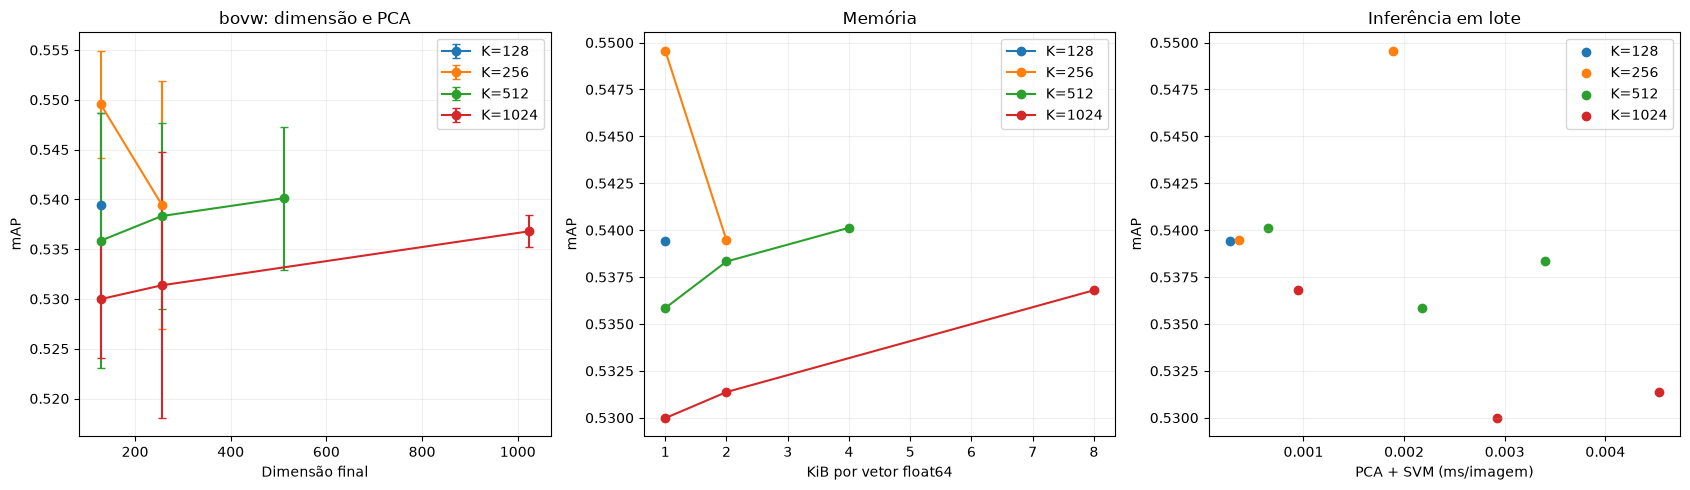

Resultados guardados em: C:\Users\guilh\Desktop\Mestrado\2ºAno\CVC\Assig#1\iacv_labs\assignment2\code\results\part3_complete


In [7]:
fig, axes = plt.subplots(len(PART3_METHODS), 3, figsize=(17, 5*len(PART3_METHODS)), squeeze=False)
for row, method in enumerate(PART3_METHODS):
    for k, group in part3_final[part3_final.method == method].groupby("K"):
        group = group.sort_values("dimensions")
        axes[row, 0].errorbar(group.dimensions, group.mAP_mean, yerr=group.mAP_std,
                              marker="o", capsize=3, label=f"K={k}")
        axes[row, 1].plot(group.feature_KiB_float64, group.mAP_mean, "o-", label=f"K={k}")
        axes[row, 2].scatter(group.inference_ms_per_image, group.mAP_mean, label=f"K={k}")
    axes[row, 0].set(xlabel="Dimensão final", ylabel="mAP", title=f"{method}: dimensão e PCA")
    axes[row, 1].set(xlabel="KiB por vetor float64", ylabel="mAP", title="Memória")
    axes[row, 2].set(xlabel="PCA + SVM (ms/imagem)", ylabel="mAP", title="Inferência em lote")
    for ax in axes[row]:
        ax.legend()
        ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(PART3_OUTPUT / "tradeoffs.png", dpi=150)
plt.show()

if not (part3_final.converged & part3_final.encoder_converged).all():
    print("Existem configurações não convergidas: interpretar como provisórias.")
print("Resultados guardados em:", PART3_OUTPUT.resolve())
